## Challenge 2: Music Genre Classification
## Tập dữ liệu: shai-music-genre-classification
## Sử dụng 3 thuật toán: LightGBM, XGBoost, Random Forest
## Độ đo: F1

### 1. Đọc dữ liệu

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

SEED = 42
TARGET = "Class"

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
sample_sub = pd.read_csv("data/sample_submission.csv")

print("Train:", train.shape, "| Test:", test.shape, "| Sample submission:", sample_sub.shape)
train.head()

Train: (14396, 18) | Test: (3600, 17) | Sample submission: (3600, 2)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


### 2. Khám phá dữ liệu EDA

In [2]:
print(train.dtypes, "\n")

miss = pd.DataFrame({"train": train.isnull().sum(), "test": test.isnull().sum().reindex(train.columns)})
print("Giá trị thiếu:")
print(miss[(miss["train"] > 0) | (miss["test"] > 0)], "\n")

feat_cols = [c for c in train.columns if c not in ("Id", TARGET)]
print("Dòng trùng hoàn toàn (bỏ Id)              :", train.drop(columns="Id").duplicated().sum())
print("Dòng giống hệt đặc trưng nhưng khác Class :", train.duplicated(feat_cols, keep=False).sum())

Id                      int64
Artist Name               str
Track Name                str
Popularity            float64
danceability          float64
energy                float64
key                   float64
loudness              float64
mode                    int64
speechiness           float64
acousticness          float64
instrumentalness      float64
liveness              float64
valence               float64
tempo                 float64
duration_in min/ms    float64
time_signature          int64
Class                   int64
dtype: object 

Giá trị thiếu:
                  train   test
Popularity          333   95.0
key                1609  405.0
instrumentalness   3541  836.0 

Dòng trùng hoàn toàn (bỏ Id)              : 0
Dòng giống hệt đặc trưng nhưng khác Class : 2060


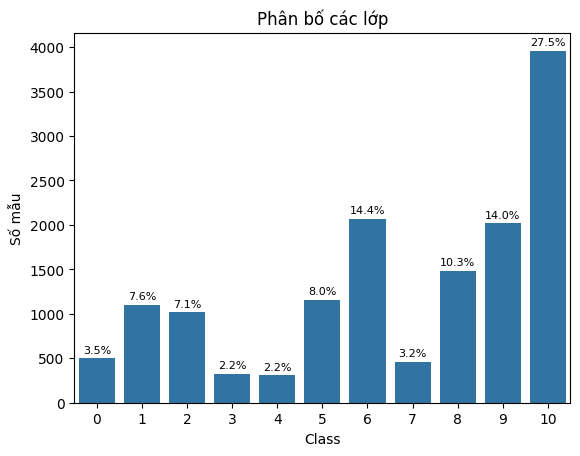

In [3]:
cnt = train[TARGET].value_counts().sort_index()
ax = sns.barplot(x=cnt.index, y=cnt.values, color="tab:blue")
for i, v in enumerate(cnt.values):
    ax.text(i, v + 60, f"{v / len(train) * 100:.1f}%", ha="center", fontsize=8)
ax.set_xlabel("Class"); ax.set_ylabel("Số mẫu"); ax.set_title("Phân bố các lớp")
plt.show()

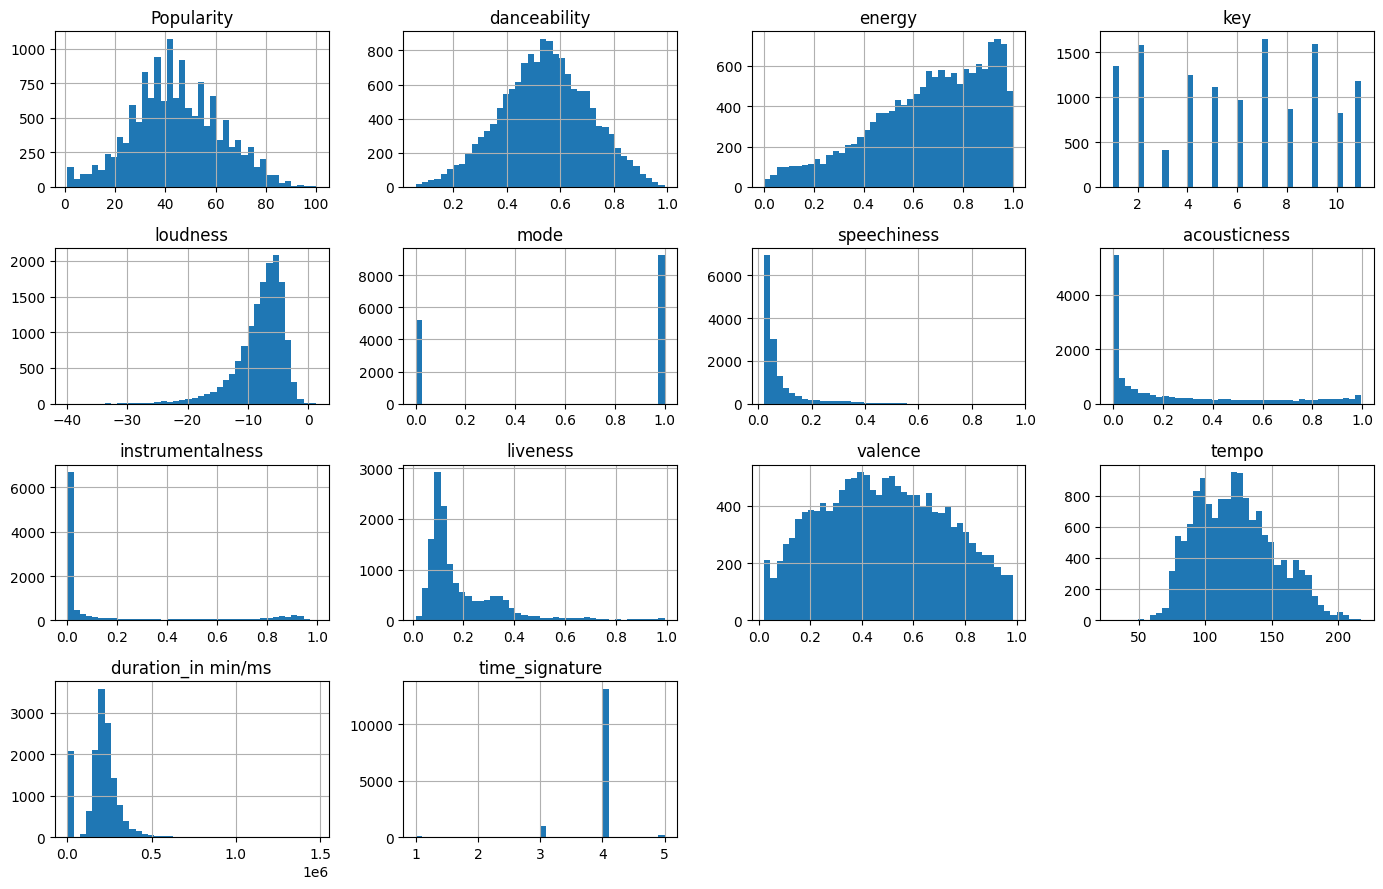

Số dòng duration < 1000 (nghi là đơn vị phút): train 2075, test 505


In [4]:
NUM_COLS = ["Popularity", "danceability", "energy", "key", "loudness", "mode", "speechiness",
            "acousticness", "instrumentalness", "liveness", "valence", "tempo",
            "duration_in min/ms", "time_signature"]

train[NUM_COLS].hist(bins=40, figsize=(14, 9))
plt.tight_layout(); plt.show()

small = (train["duration_in min/ms"] < 1000).sum()
print(f"Số dòng duration < 1000 (nghi là đơn vị phút): train {small}, test {(test['duration_in min/ms'] < 1000).sum()}")

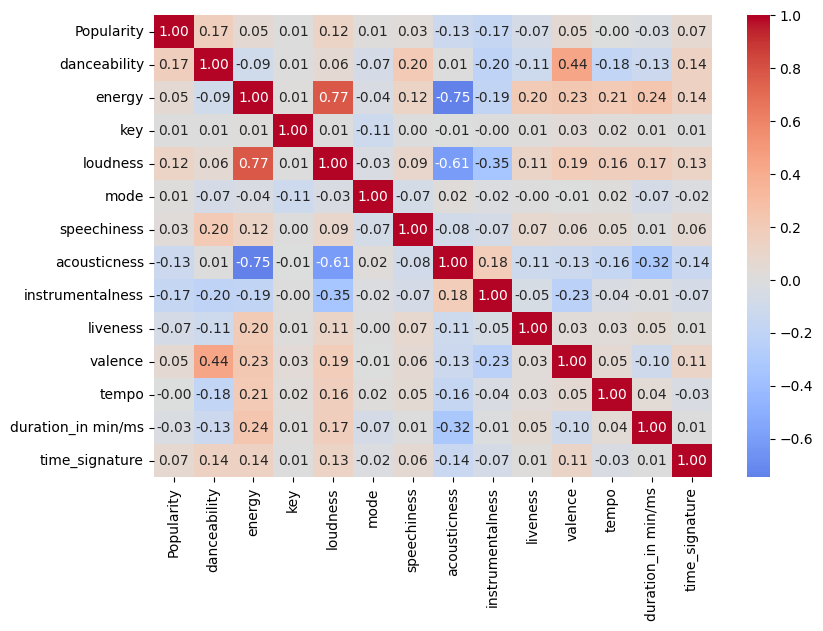

In [5]:
plt.figure(figsize=(9, 6))
sns.heatmap(train[NUM_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Nhận xét:**
- Train 14.396 dòng, test 3.600 dòng, target `Class` có 11 lớp.
- **Mất cân bằng lớp:** lớp 10 chiếm 27,5%, lớp 3 và 4 chỉ khoảng 2,2%. Do đó dùng F1 macro và xử lý mất cân bằng ở bước sau.
- **Giá trị thiếu:** `Popularity` (2,3%), `key` (11,2%), `instrumentalness` (24,6%), test thiếu tương tự.
- **Cột `duration`:** 2.075 dòng train (505 dòng test) có giá trị dưới 1000, trung vị khoảng 3,7, là đơn vị *phút* chứ không phải ms, cần đổi sang ms.
- **Trùng lặp:** không có dòng trùng hoàn toàn, nhưng 2.060 dòng giống hệt nhau về đặc trưng mà khác nhãn (cùng một bài thuộc nhiều genre). Đây là nhiễu nhãn, nên F1 không thể đạt gần 1.
- **Tương quan:** `energy` tương quan âm mạnh với `acousticness` (-0,75) và dương với `loudness` (0,77). Mô hình cây không bị ảnh hưởng nhiều.

### 3. Tiền xử lý dữ liệu

In [6]:
test_ids = test["Id"].copy()   # giữ lại để làm file nộp bài

def clean(df):
    df = df.copy()
    col = "duration_in min/ms"
    is_min = df[col] < 1000                       # giá trị đang ở đơn vị phút
    df.loc[is_min, col] = df.loc[is_min, col] * 60000
    df = df.rename(columns={col: "duration_ms"})
    return df.drop(columns=["Id", "Artist Name", "Track Name"])

train_c, test_c = clean(train), clean(test)

X = train_c.drop(columns=TARGET)
y = train_c[TARGET]
X_test = test_c

# Chia train/validation 80/20, giữ nguyên tỉ lệ các lớp
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

X_train: (11516, 14) | X_val: (2880, 14) | X_test: (3600, 14)


In [7]:
# Điền giá trị thiếu: tính từ tập train rồi áp dụng cho val và test (tránh rò rỉ dữ liệu)
fill = {
    "key": X_train["key"].mode()[0],
    "Popularity": X_train["Popularity"].median(),
    "instrumentalness": X_train["instrumentalness"].median(),
}
X_train, X_val, X_test = X_train.fillna(fill), X_val.fillna(fill), X_test.fillna(fill)

print("Còn thiếu (train/val/test):", X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), X_test.isnull().sum().sum())

Còn thiếu (train/val/test): 0 0 0


In [8]:
os.makedirs("processed", exist_ok=True)
X_train.assign(**{TARGET: y_train}).to_csv("processed/train_split.csv", index=False)
X_val.assign(**{TARGET: y_val}).to_csv("processed/val_split.csv", index=False)
X_test.assign(Id=test_ids.values).to_csv("processed/test_processed.csv", index=False)
print("Đã lưu dữ liệu vào thư mục processed/")

Đã lưu dữ liệu vào thư mục processed/


### 4. Xử lý mất cân bằng

### 5. Huấn luyện mô hình

#### 5.1 Mô hình LightGBM

#### 5.2 Mô hình XGBoost

#### 5.3 Mô hình Random Forest

### 6. Tinh chỉnh siêu tham số

### 7. Đánh giá mô hình